# ANARCI bit score and TCR CDR extraction — fully auditable

This is a new, standalone Google Colab notebook. It answers three questions:

1. What is a bit score mathematically, and where does the ANARCI value come from?
2. How are `CDR1_IMGT` and `CDR2_IMGT` obtained?
3. How are alpha (`A`) and beta (`B`) `CDR3_IMGT` sequences extracted, and what does exact grouping do?

**Important:** ANARCI does not calculate the displayed bit score by counting identities in Python. It runs HMMER `hmmscan` against chain/species profile HMMs and stores HMMER's best domain/HSP score. The notebook therefore has both (a) a small transparent HMM calculation whose terms can be inspected one by one and (b) a real ANARCI/HMMER audit that reproduces the production score.


## 1. Install the same scoring stack used by ANARCI

Run this cell once after opening the notebook in Colab. If Colab asks for a runtime restart after installation, restart and continue with the imports cell.


In [ ]:
!apt-get -qq update
!apt-get -qq install -y hmmer
!pip -q install "ANARCI==2026.2.13.2" biopython pandas matplotlib

!hmmscan -h | head -n 3


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libdivsufsort3:amd64.
(Reading database ... 118332 files and directories currently installed.)
Preparing to unpack .../libdivsufsort3_2.0.1-5_amd64.deb ...
Unpacking libdivsufsort3:amd64 (2.0.1-5) ...
Selecting previously unselected package hmmer.
Preparing to unpack .../hmmer_3.3.2+dfsg-1_amd64.deb ...
Unpacking hmmer (3.3.2+dfsg-1) ...
Setting up libdivsufsort3:amd64 (2.0.1-5) ...
Setting up hmmer (3.3.2+dfsg-1) ...
Processing triggers for man-db (2.10.2-1) ...
Processing triggers for libc-bin (2.35-0ubuntu3.13) ...
/sbin/ldconfig.real: /usr/local/lib/libtcm_debug.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfi

In [ ]:
from pathlib import Path
import importlib
import inspect
import math
import re
import subprocess

import matplotlib.pyplot as plt
import pandas as pd
from Bio import SeqIO
from IPython.display import display
from anarci import anarci as run_anarci

anarci_module = importlib.import_module("anarci.anarci")
ANARCI_PACKAGE_DIR = Path(anarci_module.__file__).resolve().parent
hmm_candidates = list(ANARCI_PACKAGE_DIR.rglob("ALL.hmm"))
if not hmm_candidates:
    raise FileNotFoundError(f"Could not find ANARCI's ALL.hmm under {ANARCI_PACKAGE_DIR}")
HMM_DB = hmm_candidates[0]
OUTPUT_DIR = Path("/content/anarci_bitscore_audit")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("ANARCI module:", anarci_module.__file__)
print("ANARCI HMM database:", HMM_DB)
print("HMMER version:")
print(subprocess.run(["hmmscan", "-h"], text=True, capture_output=True, check=True).stdout.splitlines()[1])


ANARCI module: /usr/local/lib/python3.12/dist-packages/anarci/anarci.py
ANARCI HMM database: /usr/local/lib/python3.12/dist-packages/anarci/dat/HMMs/ALL.hmm
HMMER version:
# HMMER 3.3.2 (Nov 2020); http://hmmer.org/


## 2. Upload the FASTA and choose the screenshot examples

The default searches for `1AO7_4` and `1AO7_5`, the alpha and beta examples visible in the first screenshot. Change `TARGET_QUERIES` to audit other records. A query can be any unique substring of the FASTA identifier or description.


In [ ]:
from google.colab import files

TARGET_QUERIES = ["1AO7_4", "1AO7_5"]

uploaded = files.upload()
fasta_names = [name for name in uploaded if name.lower().endswith((".fa", ".faa", ".fasta", ".fas"))]
if not fasta_names:
    raise ValueError("Upload a protein FASTA file (.fa, .faa, .fasta, or .fas).")
INPUT_FASTA = Path(fasta_names[0])
records = list(SeqIO.parse(str(INPUT_FASTA), "fasta"))
if not records:
    raise ValueError(f"No FASTA records were found in {INPUT_FASTA}.")

def clean_protein(record):
    sequence = re.sub(r"[^A-Z]", "", str(record.seq).upper().replace("*", ""))
    if not sequence:
        raise ValueError(f"Record {record.id!r} has no amino-acid sequence.")
    return sequence

selected_records = []
for query in TARGET_QUERIES:
    matches = [r for r in records if query.lower() in f"{r.id} {r.description}".lower()]
    if len(matches) == 1:
        selected_records.append(matches[0])
    elif len(matches) == 0:
        print(f"No record matched {query!r}; it was skipped.")
    else:
        raise ValueError(f"{query!r} matched {len(matches)} records. Use a more specific substring.")

if not selected_records:
    selected_records = records[:2]
    print("The requested examples were absent, so the first two FASTA records were selected.")

selection_df = pd.DataFrame({
    "record_id": [r.id for r in selected_records],
    "length": [len(clean_protein(r)) for r in selected_records],
    "description": [r.description for r in selected_records],
})
display(selection_df)


Saving all_sequences.fasta to all_sequences.fasta


,record_id,length,description
0,1AO7_4|Chain,204,1AO7_4|Chain D|T CELL RECEPTOR ALPHA|Homo sapi...
1,1AO7_5|Chain,245,1AO7_5|Chain E|T CELL RECEPTOR BETA|Homo sapie...


## 3. Bit score mathematics, calculated line by line

For a **fixed HMM state path** $\pi$, a bit score is a base-2 log odds ratio:

$$S_{\mathrm{path}}=\log_2\frac{P(x,\pi\mid H)}{P(x,\pi\mid N)}
=\sum_i\log_2\frac{e_i(x_i)}{f(x_i)}
+\sum_j\log_2\frac{t_j^{(H)}}{t_j^{(N)}}.$$

Here, $e_i(x_i)$ is the profile probability of the observed amino acid at profile position $i$, $f(x_i)$ is its null/background probability, and the $t$ terms are transition probabilities. Positive contributions favor the profile; negative contributions favor the null model. One additional bit means twofold larger odds.

The cell below is an **exact calculation for a deliberately small teaching profile**. It is not an attempt to recreate ANARCI's trained profile from the displayed CDR strings. Production HMMER uses a Plan7 profile, local entry/exit, insertions/deletions, the Forward sum over possible paths, and composition-bias correction.


,position,aa,profile_emit_p,null_emit_p,emission_bits,profile_transition_p,null_transition_p,transition_bits,step_bits
0,1,C,0.45,0.05,3.1699,0.90,0.50,0.848,4.0179
1,2,A,0.28,0.05,2.4854,0.95,0.95,0.000,2.4854
2,3,S,0.32,0.05,2.6781,0.95,0.95,0.000,2.6781
3,4,S,0.30,0.05,2.5850,0.95,0.95,0.000,2.5850
4,5,L,0.22,0.05,2.1375,0.95,0.95,0.000,2.1375
5,6,G,0.18,0.05,1.8480,0.95,0.95,0.000,1.8480
6,7,Q,0.20,0.05,2.0000,0.95,0.95,0.000,2.0000
7,8,E,0.25,0.05,2.3219,0.95,0.95,0.000,2.3219
8,9,T,0.24,0.05,2.2630,0.95,0.95,0.000,2.2630
9,10,Q,0.20,0.05,2.0000,0.95,0.95,0.000,2.0000


Exact toy path bit score = 29.9922 bits
Profile:null odds for this path = 2^29.9922 = 1,067,950,698.1:1


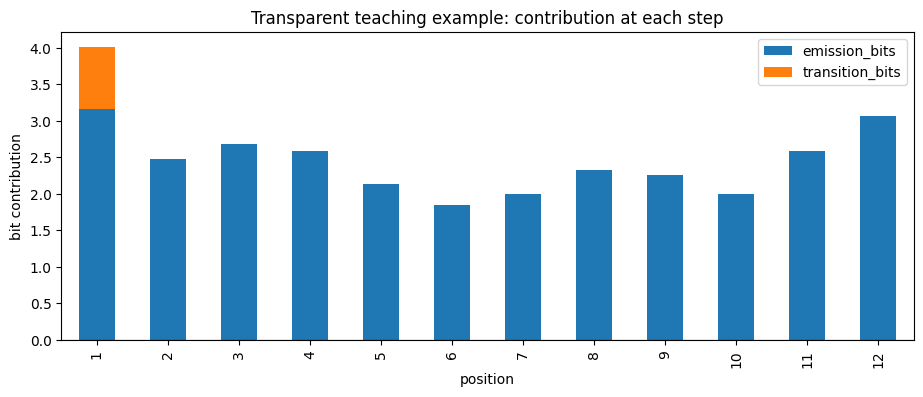

In [ ]:
toy_sequence = "CASSLGQETQYF"
# Profile probability assigned to the observed residue at each position.
profile_emission_p = [0.45, 0.28, 0.32, 0.30, 0.22, 0.18, 0.20, 0.25, 0.24, 0.20, 0.30, 0.42]
# A uniform null makes every arithmetic step easy to verify.
null_emission_p = [1 / 20] * len(toy_sequence)
# One transition enters each match state. These chosen probabilities define this teaching HMM.
profile_transition_p = [0.90] + [0.95] * (len(toy_sequence) - 1)
null_transition_p = [0.50] + [0.95] * (len(toy_sequence) - 1)

toy_rows = []
for i, (aa, ep, np_, tp, ntp) in enumerate(zip(
    toy_sequence, profile_emission_p, null_emission_p, profile_transition_p, null_transition_p
), start=1):
    emission_bits = math.log2(ep / np_)
    transition_bits = math.log2(tp / ntp)
    toy_rows.append({
        "position": i, "aa": aa,
        "profile_emit_p": ep, "null_emit_p": np_,
        "emission_bits": emission_bits,
        "profile_transition_p": tp, "null_transition_p": ntp,
        "transition_bits": transition_bits,
        "step_bits": emission_bits + transition_bits,
    })

toy_score_table = pd.DataFrame(toy_rows)
toy_bit_score = toy_score_table["step_bits"].sum()
display(toy_score_table.round(4))
print(f"Exact toy path bit score = {toy_bit_score:.4f} bits")
print(f"Profile:null odds for this path = 2^{toy_bit_score:.4f} = {2**toy_bit_score:,.1f}:1")

ax = toy_score_table.plot.bar(x="position", y=["emission_bits", "transition_bits"], stacked=True, figsize=(11, 4))
ax.set_ylabel("bit contribution")
ax.set_title("Transparent teaching example: contribution at each step")
plt.axhline(0, color="black", linewidth=0.8)
plt.show()


## 4. Run real ANARCI and keep every numbered residue

ANARCI first chooses the best species/chain profile HMM. Its reported `bitscore` is read from HMMER's HSP/domain result. The numbering that follows gives each occupied residue an IMGT integer position plus an optional insertion code.


In [ ]:
anarci_input = [(record.id, clean_protein(record)) for record in selected_records]
numbered, alignment_details, hit_tables = run_anarci(
    anarci_input,
    scheme="imgt",
    allow={"A", "B"},
    assign_germline=False,
    output=False,
    ncpu=2,
)

domain_results = []
for (source_id, sequence), numbered_item, details_item in zip(anarci_input, numbered, alignment_details):
    if not numbered_item or not details_item:
        print(f"No accepted ANARCI domain for {source_id!r}.")
        continue
    for domain_index, (domain, info) in enumerate(zip(numbered_item, details_item)):
        numbered_domain, sequence_start, sequence_end = domain
        model_id = info.get("id") or f"{info.get('species')}_{info.get('chain_type')}"
        domain_results.append({
            "source_id": source_id,
            "raw_sequence": sequence,
            "domain_index": domain_index,
            "sequence_start": sequence_start,
            "sequence_end": sequence_end,
            "model_id": model_id,
            "species": info.get("species"),
            "chain_type": info.get("chain_type"),
            "anarci_bitscore": float(info["bitscore"]),
            "anarci_evalue": float(info["evalue"]),
            "numbered_domain": numbered_domain,
        })

if not domain_results:
    raise RuntimeError("ANARCI did not accept any selected sequence as an IG/TR variable domain.")

anarci_summary = pd.DataFrame([{k: v for k, v in row.items() if k != "numbered_domain"} for row in domain_results])
display(anarci_summary)


,source_id,raw_sequence,domain_index,sequence_start,sequence_end,model_id,species,chain_type,anarci_bitscore,anarci_evalue
0,1AO7_4|Chain,KEVEQNSGPLSVPEGAIASLNCTYSDRGSQSFFWYRQYSGKSPELI...,0,0,109,human_A,human,A,129.9,8.100000e-41
1,1AO7_5|Chain,NAGVTQTPKFQVLKTGQSMTLQCAQDMNHEYMSWYRQDPGMGLRLI...,0,0,114,human_B,human,B,143.1,7.000000e-45


### Confirm the score's provenance in the installed ANARCI code

This prints the installed source lines in which ANARCI copies the HMMER parser's `hsp.bitscore` into its hit table. This is why the value is a HMMER domain/HSP bit score, not a CDR similarity percentage.


In [ ]:
parse_source = inspect.getsource(anarci_module._parse_hmmer_query).splitlines()
for line_number, line in enumerate(parse_source, start=1):
    if "hsp.bitscore" in line or "hit_table" in line or "query.hsps" in line:
        print(f"{line_number:>4}: {line}")


  11:     hit_table = [ ['id', 'description', 'evalue', 'bitscore', 'bias', 
  18:     if query.hsps: # We have some hits
  22:             #hit_correct_species = [hsp for hsp in query.hsps if hsp.hit_id.startswith(hmmer_species) and hsp.bitscore >= bit_score_threshold]
  24:             for hsp in query.hsps:
  25:                 if hsp.bitscore >= bit_score_threshold:
  34:                 hsp_list = query.hsps
  36:             hsp_list = query.hsps
  40:             if hsp.bitscore >= bit_score_threshold: # Only look at those with hits that are over the threshold bit-score.
  45:                 hit_table.append( [ hsp.hit_id, hsp.hit_description, hsp.evalue, hsp.bitscore, hsp.bias, hsp.query_start, hsp.query_end] )
  48:                     top_descriptions.append(  dict( list(zip(hit_table[0], hit_table[-1])) ) ) # Add the last added to the descriptions list. 
  64:     return hit_table, state_vectors, top_descriptions


## 5. Re-run `hmmscan` directly and reproduce ANARCI's number

`--tblout` reports a full-target score; `--domtblout` reports individual domain scores. ANARCI stores the HSP/domain score. For a normal single TCR variable domain, the two HMMER scores are usually close, but they are not required to be identical.


In [ ]:
audit_fasta = OUTPUT_DIR / "selected_sequences.fasta"
audit_id_to_source = {}
with audit_fasta.open("w") as handle:
    for index, record in enumerate(selected_records):
        audit_id = f"audit_{index}"
        audit_id_to_source[audit_id] = record.id
        handle.write(f">{audit_id}\n{clean_protein(record)}\n")

tblout_path = OUTPUT_DIR / "hmmscan.tblout"
domtblout_path = OUTPUT_DIR / "hmmscan.domtblout"
textout_path = OUTPUT_DIR / "hmmscan.txt"
command = [
    "hmmscan", "--noali",
    "--tblout", str(tblout_path),
    "--domtblout", str(domtblout_path),
    "-o", str(textout_path),
    str(HMM_DB), str(audit_fasta),
]
completed = subprocess.run(command, text=True, capture_output=True, check=True)
print("Ran:", " ".join(command))
print("Saved raw HMMER output under", OUTPUT_DIR)


Ran: hmmscan --noali --tblout /content/anarci_bitscore_audit/hmmscan.tblout --domtblout /content/anarci_bitscore_audit/hmmscan.domtblout -o /content/anarci_bitscore_audit/hmmscan.txt /usr/local/lib/python3.12/dist-packages/anarci/dat/HMMs/ALL.hmm /content/anarci_bitscore_audit/selected_sequences.fasta
Saved raw HMMER output under /content/anarci_bitscore_audit


In [ ]:
def parse_tblout(path):
    rows = []
    for line in Path(path).read_text().splitlines():
        if not line or line.startswith("#"):
            continue
        p = line.split()
        if len(p) < 18:
            continue
        rows.append({
            "target_name": p[0], "query_name": p[2],
            "full_evalue": float(p[4]), "full_score": float(p[5]), "full_bias": float(p[6]),
            "best_domain_evalue": float(p[7]), "best_domain_score": float(p[8]),
            "best_domain_bias": float(p[9]),
        })
    return pd.DataFrame(rows)

def parse_domtblout(path):
    rows = []
    for line in Path(path).read_text().splitlines():
        if not line or line.startswith("#"):
            continue
        p = line.split()
        if len(p) < 22:
            continue
        rows.append({
            "target_name": p[0], "query_name": p[3],
            "full_evalue": float(p[6]), "full_score": float(p[7]), "full_bias": float(p[8]),
            "domain_number": int(p[9]), "domain_count": int(p[10]),
            "conditional_evalue": float(p[11]), "independent_evalue": float(p[12]),
            "domain_score": float(p[13]), "domain_bias": float(p[14]),
            "hmm_from": int(p[15]), "hmm_to": int(p[16]),
            "ali_from": int(p[17]), "ali_to": int(p[18]),
            "env_from": int(p[19]), "env_to": int(p[20]), "accuracy": float(p[21]),
        })
    return pd.DataFrame(rows)

hmmer_targets = parse_tblout(tblout_path)
hmmer_domains = parse_domtblout(domtblout_path)
display(hmmer_targets.head())
display(hmmer_domains.head())


,target_name,query_name,full_evalue,full_score,full_bias,best_domain_evalue,best_domain_score,best_domain_bias
0,human_A,audit_0,4.900000e-41,130.6,0.3,8.100000e-41,129.9,0.1
1,mouse_A,audit_0,1.600000e-39,125.7,0.7,2.500000e-39,125.1,0.1
2,human_D,audit_0,5.500000e-30,94.9,0.0,9.700000e-30,94.1,0.0
3,mouse_D,audit_0,3.200000e-28,89.7,0.2,6.700000e-28,88.6,0.0
4,human_B,audit_0,3.900000e-19,59.9,0.1,9.700000e-19,58.6,0.1


,target_name,query_name,full_evalue,full_score,full_bias,domain_number,domain_count,conditional_evalue,independent_evalue,domain_score,domain_bias,hmm_from,hmm_to,ali_from,ali_to,env_from,env_to,accuracy
0,human_A,audit_0,4.900000e-41,130.6,0.3,1,2,8.100000e-41,8.100000e-41,129.9,0.1,3,128,2,110,1,110,0.97
1,human_A,audit_0,4.900000e-41,130.6,0.3,2,2,9.100000e+00,9.100000e+00,-2.8,0.0,94,102,145,153,124,161,0.67
2,mouse_A,audit_0,1.600000e-39,125.7,0.7,1,2,2.500000e-39,2.500000e-39,125.1,0.1,3,128,2,110,1,110,0.97
3,mouse_A,audit_0,1.600000e-39,125.7,0.7,2,2,5.600000e+00,5.600000e+00,-2.1,0.1,92,102,143,153,125,160,0.74
4,human_D,audit_0,5.500000e-30,94.9,0.0,1,1,9.700000e-30,9.700000e-30,94.1,0.0,3,128,2,110,1,110,0.93


In [ ]:
comparison_rows = []
source_to_audit = {source: audit_id for audit_id, source in audit_id_to_source.items()}
for result in domain_results:
    audit_id = source_to_audit[result["source_id"]]
    model_id = result["model_id"]
    domain_match = hmmer_domains[(hmmer_domains.query_name == audit_id) & (hmmer_domains.target_name == model_id)]
    target_match = hmmer_targets[(hmmer_targets.query_name == audit_id) & (hmmer_targets.target_name == model_id)]
    if domain_match.empty:
        raise RuntimeError(f"No raw HMMER domain row matched query={audit_id}, model={model_id}.")
    best_domain = domain_match.sort_values("domain_score", ascending=False).iloc[0]
    best_target = target_match.iloc[0] if not target_match.empty else None
    hmmer_score = float(best_domain.domain_score)
    comparison_rows.append({
        "source_id": result["source_id"],
        "chain_type": result["chain_type"],
        "profile_HMM": model_id,
        "ANARCI_hsp_bitscore": result["anarci_bitscore"],
        "HMMER_domain_score": hmmer_score,
        "difference": hmmer_score - result["anarci_bitscore"],
        "HMMER_domain_bias": float(best_domain.domain_bias),
        "HMMER_full_score": float(best_target.full_score) if best_target is not None else float(best_domain.full_score),
        "HMMER_full_bias": float(best_target.full_bias) if best_target is not None else float(best_domain.full_bias),
        "domain_alignment_in_input": f"{int(best_domain.ali_from)}-{int(best_domain.ali_to)}",
    })

score_audit_df = pd.DataFrame(comparison_rows)
display(score_audit_df)
if (score_audit_df["difference"].abs() <= 0.11).all():
    print("PASS: raw HMMER domain scores reproduce ANARCI scores to reported precision.")
else:
    print("Inspect version/model/rounding differences above; the raw HMMER files were retained for audit.")


,source_id,chain_type,profile_HMM,ANARCI_hsp_bitscore,HMMER_domain_score,difference,HMMER_domain_bias,HMMER_full_score,HMMER_full_bias,domain_alignment_in_input
0,1AO7_4|Chain,A,human_A,129.9,129.9,0.0,0.1,130.6,0.3,2-110
1,1AO7_5|Chain,B,human_B,143.1,143.1,0.0,0.0,144.2,0.0,1-115


PASS: raw HMMER domain scores reproduce ANARCI scores to reported precision.


### What the production score means

For production HMMER, the conceptual score is

$$S_{\mathrm{reported}} \approx \log_2\frac{\sum_{\pi}P(x,\pi\mid H)}{P(x\mid N)} - B_{\mathrm{null2}},$$

where the numerator sums possible HMM paths with the Forward algorithm and $B_{\mathrm{null2}}$ is the composition-bias correction in bits. Domain boundaries and scores are finalized by Forward/Backward postprocessing. Standard HMMER output does not expose a unique additive, per-residue breakdown of the final Forward domain score. The exact reproducible record is therefore the profile database, HMMER version/options, query sequence, raw `domtblout`, and reported domain score—all saved here.

The next experiment turns off only the null2 correction. Its purpose is to show how much composition correction changed the reported score; it does **not** replace ANARCI's default score.


In [ ]:
nonull2_domtblout = OUTPUT_DIR / "hmmscan_nonull2.domtblout"
nonull2_textout = OUTPUT_DIR / "hmmscan_nonull2.txt"
nonull2_command = [
    "hmmscan", "--noali", "--nonull2",
    "--domtblout", str(nonull2_domtblout),
    "-o", str(nonull2_textout),
    str(HMM_DB), str(audit_fasta),
]
subprocess.run(nonull2_command, text=True, capture_output=True, check=True)
hmmer_domains_nonull2 = parse_domtblout(nonull2_domtblout)

bias_rows = []
for result in domain_results:
    audit_id = source_to_audit[result["source_id"]]
    model_id = result["model_id"]
    default_row = hmmer_domains[(hmmer_domains.query_name == audit_id) & (hmmer_domains.target_name == model_id)].sort_values("domain_score", ascending=False).iloc[0]
    uncorrected_row = hmmer_domains_nonull2[(hmmer_domains_nonull2.query_name == audit_id) & (hmmer_domains_nonull2.target_name == model_id)].sort_values("domain_score", ascending=False).iloc[0]
    bias_rows.append({
        "source_id": result["source_id"],
        "default_domain_score": float(default_row.domain_score),
        "default_domain_bias": float(default_row.domain_bias),
        "score_plus_reported_bias": float(default_row.domain_score + default_row.domain_bias),
        "nonull2_domain_score": float(uncorrected_row.domain_score),
        "nonull2_minus_default": float(uncorrected_row.domain_score - default_row.domain_score),
    })
bias_experiment_df = pd.DataFrame(bias_rows)
display(bias_experiment_df)


,source_id,default_domain_score,default_domain_bias,score_plus_reported_bias,nonull2_domain_score,nonull2_minus_default
0,1AO7_4|Chain,129.9,0.1,130.0,130.0,0.1
1,1AO7_5|Chain,143.1,0.0,143.1,143.1,0.0


## 6. How CDR1 and CDR2 were found in the first screenshot

They were not found by slicing fixed offsets in the original protein sequence. ANARCI first aligned each sequence to its selected profile HMM and assigned **IMGT numbering**. Your extraction code then selected occupied numbered residues in these windows:

| output | IMGT positions selected | boundary rule |
|---|---:|---|
| `CDR1_IMGT` | 27–38 | after FR1 position 26 and before FR2 position 39 |
| `CDR2_IMGT` | 56–65 | after FR2 position 55 and before FR3 position 66 |
| `CDR3_IMGT` | 105–117 | after conserved Cys104 and before J-Phe/Trp118 |

A window can contain unoccupied IMGT positions (`-`). Those gaps are skipped. Therefore `DRGSQS` has length 6 even though CDR1's standardized window contains 12 possible position numbers. The screenshot gives the concatenated sequence and occupied-residue count; the next cell prints the actual IMGT position attached to every letter.


In [ ]:
IMGT_REGIONS = {
    "CDR1_IMGT": (27, 38),
    "CDR2_IMGT": (56, 65),
    "CDR3_IMGT": (105, 117),
}

def extract_imgt_region(numbered_domain, start, end):
    rows = []
    for ((position, insertion), amino_acid) in numbered_domain:
        if start <= int(position) <= end and amino_acid != "-":
            insertion = str(insertion).strip()
            rows.append({
                "imgt_position": f"{int(position)}{insertion}",
                "integer_position": int(position),
                "insertion_code": insertion,
                "amino_acid": amino_acid,
            })
    sequence = "".join(row["amino_acid"] for row in rows)
    columns = ["imgt_position", "integer_position", "insertion_code", "amino_acid"]
    return sequence, pd.DataFrame(rows, columns=columns)

cdr_rows = []
for result in domain_results:
    print(f"\n{result['source_id']} | chain {result['chain_type']} | HMM {result['model_id']}")
    for region_name, (start, end) in IMGT_REGIONS.items():
        sequence, position_table = extract_imgt_region(result["numbered_domain"], start, end)
        cdr_rows.append({
            "source_id": result["source_id"],
            "chain_type": result["chain_type"],
            "region": region_name,
            "sequence": sequence,
            "length": len(sequence),
            "numbered": "",
        })
        # Fill the readable numbered string separately to keep the extraction logic visible.
        cdr_rows[-1]["numbered"] = " ".join(position_table.imgt_position.astype(str) + "=" + position_table.amino_acid)
        print(f"  {region_name}: {sequence} (length {len(sequence)})")
        display(position_table)

cdr_audit_df = pd.DataFrame(cdr_rows)
display(cdr_audit_df)



1AO7_4|Chain | chain A | HMM human_A
  CDR1_IMGT: DRGSQS (length 6)


,imgt_position,integer_position,insertion_code,amino_acid
0,27,27,,D
1,28,28,,R
2,29,29,,G
3,36,36,,S
4,37,37,,Q
5,38,38,,S


  CDR2_IMGT: IYSNGD (length 6)


,imgt_position,integer_position,insertion_code,amino_acid
0,56,56,,I
1,57,57,,Y
2,58,58,,S
3,63,63,,N
4,64,64,,G
5,65,65,,D


  CDR3_IMGT: AVTTDSWGKLQ (length 11)


...

  CDR2_IMGT: SVGAGI (length 6)


,imgt_position,integer_position,insertion_code,amino_acid
0,56,56,,S
1,57,57,,V
2,58,58,,G
3,63,63,,A
4,64,64,,G
5,65,65,,I


  CDR3_IMGT: ASRPGLAGGRPEQY (length 14)


,imgt_position,integer_position,insertion_code,amino_acid
0,105,105,,A
1,106,106,,S
2,107,107,,R
3,108,108,,P
4,109,109,,G
5,110,110,,L
6,111,111,,A
7,112A,112,A,G
8,112,112,,G
9,113,113,,R


,source_id,chain_type,region,sequence,length,numbered
0,1AO7_4|Chain,A,CDR1_IMGT,DRGSQS,6,27=D 28=R 29=G 36=S 37=Q 38=S
1,1AO7_4|Chain,A,CDR2_IMGT,IYSNGD,6,56=I 57=Y 58=S 63=N 64=G 65=D
2,1AO7_4|Chain,A,CDR3_IMGT,AVTTDSWGKLQ,11,105=A 106=V 107=T 108=T 109=D 110=S 113=W 114=...
3,1AO7_5|Chain,B,CDR1_IMGT,MNHEY,5,27=M 28=N 29=H 37=E 38=Y
4,1AO7_5|Chain,B,CDR2_IMGT,SVGAGI,6,56=S 57=V 58=G 63=A 64=G 65=I
5,1AO7_5|Chain,B,CDR3_IMGT,ASRPGLAGGRPEQY,14,105=A 106=S 107=R 108=P 109=G 110=L 111=A 112A...


## 7. Exactly how alpha and beta CDR3s are extracted

For each accepted domain, ANARCI's best profile supplies `chain_type`:

- `A` means the domain matched an alpha-chain profile.
- `B` means the domain matched a beta-chain profile.

The extraction rule is otherwise identical: keep every occupied IMGT residue whose integer position is 105 through 117, preserve the order (including insertion-coded positions such as 111A or 112A), and concatenate the amino acids. This `CDR3_IMGT` convention excludes conserved Cys104 and the J-Phe/Trp at 118. Some non-IMGT TCR pipelines use a broader CDR3 convention that includes those anchors, so always state the numbering convention.

The code in the second screenshot does **not** perform this extraction. It receives a table in which `chain_type` and `CDR3_IMGT` already exist, then groups identical strings separately within alpha and beta chains. `sequence_count` is the number of input rows in the group—not CDR3 length—and `source_ids` lists the contributing records.


In [ ]:
cdr3_df = cdr_audit_df[cdr_audit_df.region == "CDR3_IMGT"].rename(columns={"sequence": "CDR3_IMGT"})
exact_cdr3_groups = (
    cdr3_df.groupby(["chain_type", "CDR3_IMGT"], dropna=False)
    .agg(
        sequence_count=("source_id", "size"),
        source_ids=("source_id", lambda values: ";".join(map(str, values))),
    )
    .reset_index()
    .sort_values(
        ["chain_type", "sequence_count", "CDR3_IMGT"],
        ascending=[True, False, True],
    )
    .reset_index(drop=True)
)
display(exact_cdr3_groups)


,chain_type,CDR3_IMGT,sequence_count,source_ids
0,A,AVTTDSWGKLQ,1,1AO7_4|Chain
1,B,ASRPGLAGGRPEQY,1,1AO7_5|Chain


## 8. Export the audit tables

These CSVs make the reasoning reproducible outside the notebook. The raw HMMER text, `tblout`, and `domtblout` files remain in the same output directory.


In [ ]:
score_audit_df.to_csv(OUTPUT_DIR / "ANARCI_HMMER_bitscore_audit.csv", index=False)
bias_experiment_df.to_csv(OUTPUT_DIR / "HMMER_null2_bias_experiment.csv", index=False)
cdr_audit_df.to_csv(OUTPUT_DIR / "TCR_CDR_IMGT_position_audit.csv", index=False)
exact_cdr3_groups.to_csv(OUTPUT_DIR / "TCR_exact_CDR3_IMGT_groups.csv", index=False)

archive_path = Path("/content/anarci_bitscore_and_cdr_audit.zip")
subprocess.run(["zip", "-qr", str(archive_path), str(OUTPUT_DIR)], check=True)
print("Created:", archive_path)
files.download(str(archive_path))


Created: /content/anarci_bitscore_and_cdr_audit.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Bottom line

- The screenshot `bitscore` is the HMMER HSP/domain log-odds score copied by ANARCI. It is evidence for the fit to the selected full variable-domain profile, not a score calculated from CDR1/2/3 alone.
- CDR1 and CDR2 are selected after ANARCI assigns IMGT positions: 27–38 and 56–65, skipping gaps.
- Alpha versus beta comes from the selected profile HMM (`A` versus `B`); CDR3-IMGT is then positions 105–117 for either chain.
- The exact-group table groups already-extracted CDR3 strings by `(chain_type, CDR3_IMGT)` and counts source rows.

Authoritative references: [HMMER hmmscan manual](https://github.com/EddyRivasLab/hmmer/blob/master/documentation/man/hmmscan.man.in), [HMMER tutorial](https://github.com/EddyRivasLab/hmmer/blob/master/documentation/userguide/tutorial.tex), and [IMGT V-domain numbering](https://www.imgt.org/IMGTScientificChart/Numbering/IMGTIGVLsuperfamily.html).
